# Personalized monitors
A monitor has four building blocks: **what to watch** (sites of a company, a commodity or a portfolio),
**which signal** (disasters near a site, activity from imagery, prediction market moves), **when to trigger**
(threshold, change against normal, combination) and **what happens** (alert, short report, watchlist).

Example from the product description: a fund holding copper miners is alerted if a disaster hits within 30 km of a
mine producing more than 10% of a company's output **and** activity at the site falls more than 20% below its
4 week average. Mine coordinates are approximate public locations; output shares and activity series are illustrative.
Free feeds keep monitors cheap: USGS earthquakes and NASA FIRMS fires are checked live below.

In [2]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from altinfo import gap, satellite, earnings, scoring, charts, valuation, eventbeta as eb
from altinfo.charts import NAVY, BLUE, RED, GREY
charts.style()
RAW = ROOT / "data" / "raw"
SNAP = json.load(open(ROOT / "data" / "snapshot_2026-11-09.json"))
LIVE = (RAW / "prices.csv").exists()
print("Mode:", "LIVE (data/raw)" if LIVE else "SNAPSHOT (figures of 9 Nov 2026; run scripts/fetch_data.py for live data)")
def kalshi_live(series):
    """Open Kalshi markets of a series with a mid price (bid/ask midpoint, else last trade)."""
    km = pd.read_csv(RAW / "kalshi_markets.csv")
    m = km[km["series"] == series].copy()
    mid = (m["yes_bid_dollars"] + m["yes_ask_dollars"]) / 2
    tight = (m["yes_ask_dollars"] - m["yes_bid_dollars"]).le(0.10) & m["yes_ask_dollars"].gt(0)
    m["mid"] = mid.where(tight, m["last_price_dollars"])
    return m
def poly_live(pattern):
    pm = pd.read_csv(RAW / "polymarket_markets.csv")
    return pm[pm.question.str.contains(pattern, case=False, na=False, regex=True) & (pm.closed != True)].sort_values("volume", ascending=False)
def live_calls(today="2026-11-10"):
    """The calls registered in the reports, with the market probability updated to the latest live data."""
    calls = pd.DataFrame(SNAP["calls"]).assign(asset=["NVDA", "BRENT"], date=["2026-11-17", "2026-11-30"],
                                                confidence="medium", date_asof=pd.Timestamp(today))
    calls["market_week_ago"] = [SNAP["nvda"]["real"]["polymarket_beat_history"]["2026-11-03"], np.nan]
    if LIVE:
        cd = pd.read_csv(RAW / "kalshi_candles.csv", parse_dates=["date"])
        cd = cd[cd.ticker.str.startswith("KXBRENTMON-26NOV30")].copy()
        cd["strike"] = cd.ticker.str.extract(r"-T([\d.]+)$")[0].astype(float)
        daily = cd.dropna(subset=["price"]).groupby("date").apply(lambda d: gap.ladder_prob_above(d.strike, d.price, 96), include_groups=False)
        bm = kalshi_live("KXBRENTMON").dropna(subset=["floor_strike", "mid"])
        calls.loc[calls.asset == "BRENT", "market"] = gap.ladder_prob_above(bm.floor_strike, bm.mid, 96)
        calls.loc[calls.asset == "BRENT", "market_week_ago"] = daily.loc[:pd.Timestamp(today) - pd.Timedelta(days=7)].iloc[-1]
        nb_ = poly_live(r"N[Vv][Ii][Dd][Ii][Aa].*beat|NVDA.*beat")
        if len(nb_):
            calls.loc[calls.asset == "NVDA", "market"] = float(nb_["price"].iloc[0])
    return calls
def load_prices():
    p = pd.read_csv(RAW / "prices.csv")
    p["date"] = pd.to_datetime(p["date"], format="mixed").dt.normalize()
    return p.pivot_table(index="date", columns="ticker", values="close").sort_index()

Mode: LIVE (data/raw)


In [3]:
from altinfo import monitors
from altinfo.coverage import COPPER_MINES
mines = pd.DataFrame(COPPER_MINES)
mines["owners"] = mines["owners"].map(lambda d: ", ".join(f"{k} {v:.0%} of output" for k, v in d.items()))
mines[["site", "country", "lat", "lon", "owners"]].rename(columns={"site": "Mine", "country": "Country", "lat": "Latitude",
                                                                    "lon": "Longitude", "owners": "Company exposure (illustrative)"})

Mine,Country,Latitude,Longitude,Company exposure (illustrative)
Grasberg,Indonesia,-4.05,137.11,FCX 35% of output
Escondida,Chile,-24.27,-69.07,BHP 55% of output
Collahuasi,Chile,-20.98,-68.64,GLEN 20% of output
El Teniente,Chile,-34.09,-70.35,Codelco 25% of output
Cerro Verde,Peru,-16.53,-71.59,FCX 20% of output
Antamina,Peru,-9.54,-77.05,TECK 25% of output
Las Bambas,Peru,-14.1,-72.32,MMG 70% of output
Kamoa-Kakula,DR Congo,-10.77,25.88,IVN 90% of output
Tenke Fungurume,DR Congo,-10.58,26.18,CMOC 40% of output


**How to read it.** The copper mines the monitor watches, with their location and the share of each company's copper output that comes from them (illustrative figures). A problem at a mine that is a large share of a company's output is what moves its shares.

## 1. Live check: earthquakes of the last 30 days near the mines (USGS feed)

In [5]:
qf = RAW / "usgs_quakes.csv"
quakes = pd.read_csv(qf, parse_dates=["time"]) if qf.exists() else pd.DataFrame(columns=["time", "mag", "place", "lat", "lon"])
print(f"{len(quakes)} earthquakes M4.5+ in the last 30 days")
for r in (30, 150, 300):
    near = monitors.disasters_near(COPPER_MINES, quakes, radius_km=r)
    print(f"within {r:>3} km of a watched mine: {len(near)}")
nq = monitors.disasters_near(COPPER_MINES, quakes, radius_km=300).sort_values("km").head(10)
nq.assign(time=pd.to_datetime(nq["time"], utc=True).dt.strftime("%d %b %Y %H:%M")).rename(columns={"site": "Mine", "time": "Time (UTC)", "mag": "Magnitude",
                                                                         "km": "Distance, km", "place": "Location"})

664 earthquakes M4.5+ in the last 30 days
within  30 km of a watched mine: 0
within 150 km of a watched mine: 6
within 300 km of a watched mine: 22


Mine,Time (UTC),Magnitude,"Distance, km",Location
Collahuasi,07 Nov 2026 10:53,4.5,69.1,"57 km SW of Ollagüe, Chile"
Collahuasi,26 Oct 2026 19:36,4.9,70.9,"100 km E of La Tirana, Chile"
Collahuasi,01 Nov 2026 01:24,4.5,82.6,"55 km SSW of Ollagüe, Chile"
Collahuasi,22 Oct 2026 21:37,4.5,88.5,"55 km S of Ollagüe, Chile"
Cerro Verde,11 Oct 2026 13:42,5.3,136.1,"28 km SSW of Camaná, Peru"
Collahuasi,17 Oct 2026 16:52,4.6,149.5,"88 km SSW of Uyuni, Bolivia"
Collahuasi,14 Oct 2026 03:11,4.9,181.3,"14 km WSW of La Tirana, Chile"
Antamina,02 Nov 2026 15:28,5.1,183.6,"50 km WSW of Huarmey, Peru"
Escondida,19 Oct 2026 07:33,4.5,199.7,"79 km W of San Antonio de los Cobres, Argentina"
Cerro Verde,25 Oct 2026 17:11,4.7,206.7,"19 km NE of Atico, Peru"


**How to read it.** The live check: earthquakes of magnitude 4.5 or more in the last 30 days (from the US Geological Survey) and how far each one was from a watched mine. An alert needs a quake within 30 km; the wider distances show that the feed works.

## 2. Replay: the Grasberg mud rush (September 2025)
On 8 September 2025 a mud rush at Freeport's Grasberg Block Cave stopped operations at one of the world's largest
copper mines. No earthquake was involved, so the monitor fires on the activity leg. The activity series is a
prototype (trucks and staff parking counted from imagery); prices are real.

In [7]:
days = pd.date_range("2025-06-01", "2025-11-30")
rng = np.random.default_rng(3)
act = pd.Series(100 + rng.normal(0, 4, len(days)), index=days)
act.loc["2025-09-09":] = act.loc["2025-09-09":] * 0.45          # operations halted after the mud rush
activity = {"Grasberg": act}
chg = monitors.activity_drop(act)
first = chg[chg <= -0.20].index[0]
print("Activity first more than 20% below its 4 week average on", first.date())
px = load_prices() if LIVE else pd.DataFrame()
m = monitors.Monitor("Copper supply disruption", COPPER_MINES, monitors.copper_rule)
alerts = m.run(activity=activity, prices=px, asof=first, horizon=first + pd.Timedelta(days=30))
alerts.rename(columns={"level": "Level", "site": "Mine", "country": "Country", "trigger": "Trigger", "output_at_risk": "Output at risk",
                       "moves_since": "Price move, next 30 days", "likely_gain": "Likely to gain", "likely_lose": "Likely to lose",
                       "channels": "Sent by"})

Activity first more than 20% below its 4 week average on 2025-09-09


Level,Mine,Country,Trigger,Output at risk,"Price move, next 30 days",Likely to gain,Likely to lose,Sent by
ALERT,Grasberg,Indonesia,activity -56% vs 4w avg,FCX 35%,"FCX -1.3%, HG=F +12.8%","SCCO, TECK, BHP, GLEN, IVN, copper futures (long)","FCX, PRY.MI",email/app


**How to read it.** Replay of the Grasberg incident. The monitor fires on the day activity at the mine falls more than 20% below its usual level. The row shows the mine, why the alert fired, which company is exposed, how much the company's shares and copper prices moved in the following 30 days, and who is likely to gain (other producers) or lose (the owner and copper users such as cable makers).

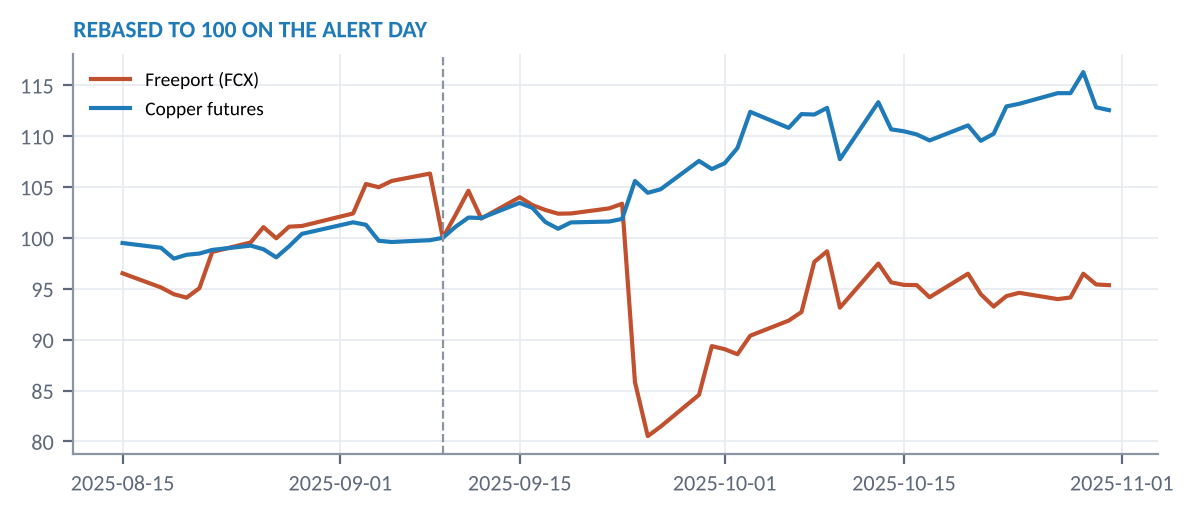

In [8]:
if LIVE and {"FCX", "HG=F"} <= set(px.columns):
    w = px[["FCX", "HG=F"]].loc["2025-08-15":"2025-10-31"].dropna(how="all").ffill()
    w = w / w.loc[:first].iloc[-1] * 100
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.plot(w.index, w["FCX"], color=RED, label="Freeport (FCX)"); ax.plot(w.index, w["HG=F"], color=BLUE, label="Copper futures")
    ax.axvline(first, color=GREY, ls="--", lw=0.8); ax.legend(frameon=False, fontsize=7)
    ax.set_title("REBASED TO 100 ON THE ALERT DAY"); plt.show()
else:
    print("Run scripts/fetch_data.py --reuse to download FCX and copper futures.")

**How to read it.** Freeport shares (red) and copper futures (blue), both set to 100 on the alert day (dashed line). Freeport fell about 20% when it declared force majeure two weeks later, while copper rose on fears of lower supply: a monitor gives a fund time to act before that move.

## 3. Prediction market monitor: alert when a linked market moves 10 points in a day

In [10]:
if LIVE:
    ph = pd.read_csv(RAW / "polymarket_history.csv", parse_dates=["date"])
    j = monitors.market_jumps(ph[ph.key.fillna("") != ""], threshold_pts=10).sort_values("date", ascending=False).head(10)
    names = {"us_invades_iran": "US invades Iran before 2027", "hormuz_normal": "Hormuz traffic normal by 31 Dec",
             "iran_regime_falls": "Iranian regime falls in 2026", "china_invades_taiwan": "China invades Taiwan before 2027",
             "us_recession_2026": "US recession in 2026"}
    display(pd.DataFrame({"Date": j["date"].dt.strftime("%d %b %Y"), "Market (Polymarket)": j["key"].map(names),
                          "Probability after": j["prob"].map("{:.0%}".format), "Move, pts": j["move_pts"].map("{:+.0f}".format)}))

Date,Market (Polymarket),Probability after,"Move, pts"
06 Jul 2026,Hormuz traffic normal by 31 Dec,60%,-14
23 May 2026,US invades Iran before 2027,18%,-12
23 May 2026,Hormuz traffic normal by 31 Dec,87%,+12
08 Apr 2026,Iranian regime falls in 2026,24%,-10
07 Apr 2026,US invades Iran before 2027,28%,-32
31 Mar 2026,US invades Iran before 2027,55%,-12
03 Mar 2026,US invades Iran before 2027,32%,+11
08 Jan 2026,Iranian regime falls in 2026,42%,+10
25 Jul 2025,China invades Taiwan before 2027,22%,-22


**How to read it.** Days when a prediction market we follow moved by 10 points or more. These are the moments a client with a monitor on that event would have been alerted.

## 4. Live check: fires near the watched places (NASA FIRMS)
Active fires of the last 7 days from the MODIS satellites, free and updated several times a day. A fire within 30 km
of a mine, a plant or a field is flagged; paid high resolution imagery would then confirm the impact.

In [12]:
from altinfo.coverage import COVERAGE
ff = RAW / "firms_fires.csv"
fires = pd.read_csv(ff, parse_dates=["time"]) if ff.exists() else None
quakes_all = quakes if len(quakes) else None
if fires is None:
    print("Run  python scripts/fetch_data.py --reuse  to download the NASA FIRMS fires and rebuild.")
else:
    allsites = list({s["site"]: s for v in COVERAGE.values() for s in v["sites"]}.values())  # each place once
    near = monitors.fires_near(allsites, fires, radius_km=30)
    print(f"{len(fires)} fires in the last 7 days within 300 km of a covered place; {near.site.nunique()} places with a fire within 30 km")
    if len(near):
        g = near.groupby("site").agg(fires=("frp", "size"), strongest_mw=("frp", "max"), nearest_km=("km", "min"), last=("time", "max"))
        g["last"] = g["last"].dt.strftime("%d %b %H:%M")
        display(g.sort_values("fires", ascending=False).rename(columns={"fires": "Fires", "strongest_mw": "Strongest, MW",
                "nearest_km": "Nearest, km", "last": "Last seen, UTC"}).rename_axis("Place").head(12))

Run  python scripts/fetch_data.py --reuse  to download the NASA FIRMS fires and rebuild.


**How to read it.** Fires detected by NASA satellites near the places we cover. Most are farm or bush fires near growing regions; a fire next to a mine or a plant is what would trigger a monitor.

## 5. A portfolio monitor
What to watch can be a whole portfolio: the platform maps each holding to the places it depends on and checks every
signal on them. Example: a fund holding Freeport, Teck, Newmont and copper futures.

In [14]:
from altinfo.coverage import sites_for_holdings
book = ["FCX", "TECK", "NEM", "copper"]
places = sites_for_holdings(book)
watch = pd.DataFrame(places)[["holding", "site", "role", "country"]]
live = monitors.site_alerts(places, quakes_all, fires)
watch = watch.merge(live.groupby("site")["alert"].apply("; ".join).reset_index(), on="site", how="left").fillna({"alert": "none"})
print(f"{len(book)} holdings -> {watch.site.nunique()} places to watch; {int((watch.alert != 'none').sum())} with a live alert")
watch.rename(columns={"holding": "Holding", "site": "Place", "role": "Role", "country": "Country", "alert": "Live alert"})

4 holdings -> 14 places to watch; 1 with a live alert


Holding,Place,Role,Country,Live alert
FCX,Grasberg,Mine,Indonesia,none
FCX,Cerro Verde,Mine,Peru,none
TECK,Antamina,Mine,Peru,none
NEM,"Carlin Trend, Nevada",Mine,United States,none
NEM,Boddington,Mine,Australia,none
copper,Grasberg,Mine,Indonesia,none
copper,Escondida,Mine,Chile,none
copper,Collahuasi,Mine,Chile,"Earthquake M4.9, 71 km away"
copper,El Teniente,Mine,Chile,none
copper,Cerro Verde,Mine,Peru,none


**How to read it.** A portfolio monitor: each holding is mapped to the mines, ports and plants it depends on, and every place is checked against the live earthquake and fire feeds.